# 01 — Construção do alvo (seções 1–5 do v5)

**Lê:** CSVs do Olist em `dados_brutos/olist/`.  
**Grava:** `order_seller_revenue`, `weekly_observed`, `weeks_info`, `corte.json`, `auditoria_alvo.json`.  
Nenhum modelo é ajustado aqui.

In [1]:
# === SETUP (idêntico em todos os notebooks; só muda NOTEBOOK) ===
NOTEBOOK = "01_alvo"
RAIZ = "/content/drive/MyDrive/tcc_fluxo"      # Colab. Localmente: caminho da pasta do projeto (ou deixe None)

import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
    !pip install -q -r {RAIZ}/requirements.txt
except ImportError:                              # fora do Colab
    RAIZ = os.environ.get("TCC_RAIZ") or None
    if RAIZ is None:
        from pathlib import Path
        RAIZ = str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").is_file()))
sys.path.insert(0, f"{RAIZ}/src")
%load_ext autoreload
%autoreload 2

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tcc_fluxo import iniciar
C, A = iniciar(RAIZ, notebook=NOTEBOOK)

AVISO de reprodutibilidade: pandas=3.1.1; referência recomendada=2.2.3
AVISO de reprodutibilidade: numpy=2.5.4; referência recomendada=2.1.3
AVISO de reprodutibilidade: scikit-learn=1.9.1; referência recomendada=1.6.1
Notebook: 01_alvo | execução: v6_modular | raiz: C:\Users\andre\OneDrive\Documentos\Projetos\Tccv2\tcc_fluxo_modular_v6


In [2]:
from tcc_fluxo import alvo, graficos

orders, payments, items = alvo.ler_olist(C.caminho("dados_olist"))
tab, status_sem_aprov = alvo.diagnostico_bruto(orders, payments, items)
display(tab)
print("Status dos pedidos sem order_approved_at:")
display(status_sem_aprov)

,Valor
Diagnóstico,
Linhas em orders,"99,441"
Linhas em payments,"103,886"
Linhas em items,"112,650"
Pedidos distintos (orders),"99,441"
Pedidos com pagamento registrado,"99,440"
Pedidos com itens,"98,666"
Vendedores com itens,"3,095"
order_approved_at ausente,160 (0.161%)
Registros de pagamento com valor 0 ou ausente,9 (0.0087%)


Status dos pedidos sem order_approved_at:


,pedidos
order_status,
canceled,141
delivered,14
created,5


### Estratégia para `order_approved_at` ausente
Regra fixada antes de olhar modelos: se a proporção de ausentes for ≤ `APPROVED_MISSING_MAX_SHARE`, esses pedidos são excluídos e a semana é definida só por `order_approved_at`; caso contrário toda a base usaria `order_purchase_timestamp`.

In [3]:
data = alvo.escolher_coluna_data(orders, C.APPROVED_MISSING_MAX_SHARE)
DATE_COL, DATE_STRATEGY = data["DATE_COL"], data["DATE_STRATEGY"]
print(f"Estratégia: {DATE_STRATEGY} | ausentes: {data['n_missing']} ({data['share_missing']:.3%})")
print("Alvo:", data["TARGET_NAME"])

Estratégia: approved | ausentes: 160 (0.161%)
Alvo: proxy de entrada bruta de caixa (pagamentos aprovados, alocados por vendedor)


## 2–3. Pagamento aprovado por pedido-vendedor e agregação semanal (seg–dom)

In [4]:
payment_by_order, item_by_seller_order, osr, resumo_filtro = alvo.receita_pedido_vendedor(
    orders, payments, items, DATE_STRATEGY)
print(resumo_filtro)
weekly_observed = alvo.agregar_semanal(osr, DATE_COL)
print(f"Linhas vendedor-semana observadas: {len(weekly_observed):,} | vendedores: {weekly_observed['seller_id'].nunique():,}")

{'linhas_antes': 100010, 'excluidas_linhas': 15, 'excluidos_pedidos': 15, 'excluidas_sem_aprovacao': 14, 'excluidas_sem_pagamento': 1, 'mantidas_linhas': 99995, 'mantidos_pedidos': 98651}
Linhas vendedor-semana observadas: 36,157 | vendedores: 3,095


## 4. Auditorias obrigatórias e reconciliação
Se algum `assert` falhar, a construção do alvo está errada e o notebook para aqui.

In [5]:
recon = alvo.auditorias(orders, payments, items, payment_by_order, item_by_seller_order,
                       osr, weekly_observed, DATE_STRATEGY)
display(recon)
print("Auditorias e reconciliação: OK")
display(alvo.composicao_status(osr))

,Valor
Reconciliação,
Soma dos pagamentos aprovados (R$),"15,971,742.3500"
Soma alocada aos vendedores (R$),"15,844,325.5700"
Diferença absoluta (R$),"127,416.7800"
Diferença percentual (%),0.7978
Pedidos aprovados com pagamento e SEM itens,629.0000
valor desses pedidos (R$),"127,416.7800"
Pedidos com valor bruto de itens = 0,0.0000
Vendedores com itens mas sem receita alocada,0.0000


Auditorias e reconciliação: OK


,pedidos,valor,participacao_valor_%
order_status,,,
delivered,96463,"15,420,507.1700",97.3251
shipped,1106,"177,136.2300",1.1180
canceled,461,"105,917.7300",0.6685
processing,301,"69,394.1100",0.4380
invoiced,312,"68,988.7600",0.4354
unavailable,6,"2,140.4900",0.0135
approved,2,241.0800,0.0015


## 5. Corte temporal: última semana completa

Último registro na base: 2018-09-03
Dias tratados como resíduo: [datetime.date(2018, 9, 3)] (1 pedidos)
Fim regular: 2018-08-29 | semanas removidas: [datetime.date(2018, 8, 27), datetime.date(2018, 9, 3)]
TEST_END: 2018-08-20 (seg) a 2018-08-26 (dom)


,pedidos,ultimo_registro,valor,domingo,completa
week_start,,,,,
2018-07-16,1498,2018-07-22 00:35:10,"248,312.7200",2018-07-22,True
2018-07-23,1743,2018-07-29 23:45:15,"293,695.1300",2018-07-29,True
2018-07-30,2079,2018-08-05 23:50:17,"334,584.6300",2018-08-05,True
2018-08-06,2002,2018-08-12 23:55:13,"330,932.9200",2018-08-12,True
2018-08-13,1677,2018-08-18 23:31:33,"265,670.2200",2018-08-19,True
2018-08-20,1335,2018-08-26 23:45:08,"188,855.4800",2018-08-26,True
2018-08-27,135,2018-08-29 15:10:26,"14,484.7700",2018-09-02,False
2018-09-03,1,2018-09-03 17:40:06,166.4600,2018-09-09,False


Pedidos na semana 2018-08-20: 1,335 = 84% da mediana das 8 semanas anteriores


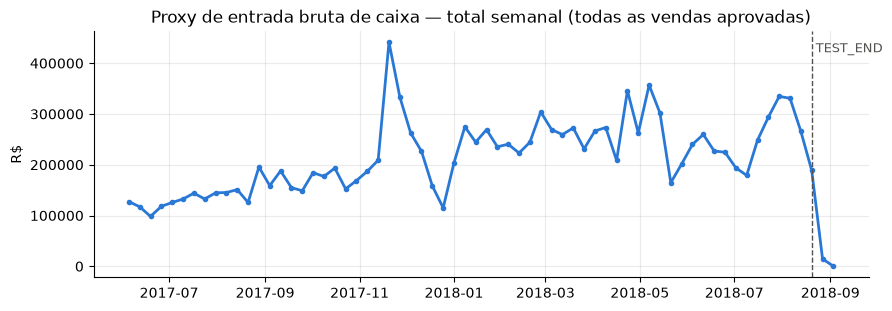

In [6]:
corte = alvo.corte_test_end(osr, weekly_observed, DATE_COL, C.TAIL_GAP_DAYS, C.TAIL_MAX_ORDERS, C.TRAIN_TARGET_END)
TEST_END = corte["TEST_END"]
print(f"Último registro na base: {corte['daily'].index.max().date()}")
print(f"Dias tratados como resíduo: {[d.date() for d in corte['residual_days']]} ({corte['residual_orders']} pedidos)")
print(f"Fim regular: {corte['last_regular_day'].date()} | semanas removidas: {[w.date() for w in corte['removed_weeks']]}")
print(f"TEST_END: {TEST_END.date()} (seg) a {(TEST_END + pd.Timedelta(days=6)).date()} (dom)")
wi = corte["weeks_info"]
display(wi.tail(8))

prev8 = wi.loc[:TEST_END - pd.Timedelta(weeks=1), "pedidos"].tail(8)
print(f"Pedidos na semana {TEST_END.date()}: {wi.loc[TEST_END, 'pedidos']:,} = "
      f"{wi.loc[TEST_END, 'pedidos'] / prev8.median():.0%} da mediana das 8 semanas anteriores")
fig = graficos.total_semanal_observado(wi, TEST_END)
A.figura(fig, "total_semanal_observado.png"); plt.show()

### Gravação dos artefatos

In [7]:
weekly_observed = weekly_observed.loc[weekly_observed["week_start"] <= TEST_END].copy()
A.salvar_df(osr, "order_seller_revenue")
A.salvar_df(weekly_observed, "weekly_observed")
A.salvar_df(wi.reset_index(), "weeks_info")
A.salvar_json({"TEST_END": TEST_END, "last_regular_day": corte["last_regular_day"],
               "residual_days": [str(d.date()) for d in corte["residual_days"]],
               "removed_weeks": [str(w.date()) for w in corte["removed_weeks"]],
               **data}, "corte")
A.salvar_json({"filtro": resumo_filtro, "reconciliacao": recon["Valor"].to_dict()}, "auditoria_alvo")

{'arquivo': 'auditoria_alvo.json',
 'sha256': '42350384bf380ddf1a70011e5e934617d0af7fb1c238108463695ea5c60ac88f',
 'notebook': '01_alvo',
 'criado_em': '2026-11-06T20:10:17',
 'entradas': {}}

In [8]:
A.finalizar()

01_alvo: leu 0 artefato(s), gravou 5.
